# DeployQ: code for the two supplied policy-loss plots

In [Google Colab](https://colab.research.google.com/), choose **File → Upload notebook**,
upload this file, and choose **Runtime → Run all**. A CPU runtime is sufficient.
No archive upload, Google Drive connection, or external dataset is needed.

**Plot 1:** ε = 0.02. **Plot 2:** ε = 0.005.
Each figure contains Proposed method, Restart, Full history, and Shared history,
with log axes, confidence bands, an upper-left within-deployment inset, and a legend inside.
Figures are 8 × 5 inches; output is vector PDF plus 300 dpi PNG.

Two modes are available:

- **replot** (default): immediately redraw the original archived numerical curves.
  The notebook embeds the original cumulative means, confidence bands, run-level
  final-window losses, and inset statistics. These were computed from the archived
  simulation arrays, not digitized from an image.
- **simulate**: rerun the full recovered experiment and then plot its results.
  Choose **paper** for the two main 50-run/200-deployment experiments,
  **quick** for a small functionality check, or **suite** for all seven archived conditions.
  Full simulations take substantially longer than replotting; runtime depends on the CPU.

Both supplied PDFs were checked against all 200 points of their four main curves.
They match the recovered October 25 experiment data to PDF coordinate rounding.
All simulation routines are included below. A ZIP of the figures, tables, and
generated data is downloaded at the end.


In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')

import importlib.util
import subprocess
import sys

required = {'numpy': 'numpy', 'scipy': 'scipy',
            'matplotlib': 'matplotlib', 'threadpoolctl': 'threadpoolctl'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import csv
import hashlib
import json
import platform
import shutil
import time
from pathlib import Path

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from threadpoolctl import threadpool_limits

print('Python:', platform.python_version(), '| NumPy:', np.__version__,
      '| SciPy:', scipy.__version__, '| Matplotlib:', matplotlib.__version__)


Python: 3.13.18 | NumPy: 2.4.6 | SciPy: 1.16.3 | Matplotlib: 3.10.0


## Settings and experiment model

Keep `RUN_MODE = 'replot'` to redraw the two supplied plots immediately.
Set it to `'simulate'` to regenerate observations and run the learners.
`RUN_PRESET` applies only to simulation. **paper** retains 50 independent runs,
200 deployments, 50 states, four actions, γ = 0.8, B = 100, H = 2²⁰,
and the recovered validation seeds. **quick** uses three runs and 12 deployments;
its results are a functionality check, not the paper's numerical results.

Every method receives the same observations within each run. Sampling is
independent and uniform over state–action pairs. Multinomial counts and
conditional binomial statistics generate exactly the corresponding sufficient
statistics without looping over every sample.

The localized benchmark hides fixed reward and transition hotspots from all learners.
At each boundary, `floor(ε × |S| × |A|)` reward entries and the same number
of transition rows change. Each changed row changes two transition entries.
Policies update on a common geometric grid and are held between updates;
the cumulative loss weights those intervals by their lengths.

**Shared-history implementation in these plots:** the black curve is archive
method 5, `Shared history (empirical)`. It takes the minimum selected history
across all reward and transition components, then fits empirical estimates
using that common window. The archive also includes a confidence-intersection
shared estimator (method 2); that variant is not plotted in the supplied PDFs.


In [2]:
RUN_MODE = 'replot'       # 'replot' or 'simulate'
RUN_PRESET = 'paper'       # 'quick', 'paper', or 'suite'
AUTO_DOWNLOAD = True      # Download the results ZIP automatically in Colab.
OUTPUT_ROOT = Path.cwd() / 'DeployQ_Results'

COMMON = dict(
    runs=50, K=200, B=100, n=50, actions=4, gamma=0.8,
    delta=0.05, checkpoints=32, grid='geometric', slide=10,
    change='joint', schedule='redraw', env_seed=31241025,
    data_seed=41241025,
)

PAPER_CONDITIONS = [
    ('localized', 2**20, 0.02),
    ('localized', 2**20, 0.005),
]
SUITE_CONDITIONS = [
    ('localized', 2**20, 0.02),
    ('localized', 2**19, 0.02),
    ('localized', 2**17, 0.02),
    ('localized', 2**15, 0.02),
    ('original', 8192, 0.02),
    ('localized', 2**20, 0.005),
    ('localized', 2**20, 0.04),
]

if RUN_PRESET == 'quick':
    COMMON.update(runs=3, K=12, B=10, checkpoints=8)
    CONDITIONS = PAPER_CONDITIONS
elif RUN_PRESET == 'paper':
    CONDITIONS = PAPER_CONDITIONS
elif RUN_PRESET == 'suite':
    CONDITIONS = SUITE_CONDITIONS
else:
    raise ValueError("RUN_PRESET must be 'quick', 'paper', or 'suite'.")

def validate_config(cfg):
    for key in ('runs', 'K', 'B', 'n', 'actions', 'H', 'checkpoints', 'slide'):
        if not isinstance(cfg[key], (int, np.integer)):
            raise ValueError(f'{key} must be an integer.')
    if cfg['runs'] < 2:
        raise ValueError('Use at least two independent runs for confidence intervals.')
    if cfg['n'] < 3 or cfg['actions'] < 1 or cfg['K'] < 1 or cfg['B'] < 1 or cfg['H'] < 1:
        raise ValueError('Require n >= 3, actions >= 1, K >= 1, B >= 1, H >= 1.')
    if cfg['checkpoints'] < 2 or cfg['slide'] < 0:
        raise ValueError('Require checkpoints >= 2 and slide >= 0.')
    if not 0 < cfg['gamma'] < 1 or not 0 < cfg['delta'] < 1:
        raise ValueError('gamma and delta must lie in (0, 1).')
    if not 0 <= cfg['epsilon'] <= 1:
        raise ValueError('epsilon must lie in [0, 1].')
    if cfg['benchmark'] == 'localized':
        if int(np.floor(cfg['epsilon'] * cfg['n'] * cfg['actions'] + 1e-9)) > max(1, int(0.2 * cfg['n'] * cfg['actions'])):
            raise ValueError('The localized change count exceeds the hotspot size.')

CONFIGS = [COMMON | dict(benchmark=b, H=h, epsilon=e) for b, h, e in CONDITIONS]
for cfg in CONFIGS:
    validate_config(cfg)

if RUN_MODE not in ('replot', 'simulate'):
    raise ValueError("RUN_MODE must be 'replot' or 'simulate'.")
RUN_DIR = OUTPUT_ROOT / RUN_MODE / (RUN_PRESET if RUN_MODE == 'simulate' else 'original_plots')
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f'Preset: {RUN_PRESET} | {COMMON["runs"]} runs | '
      f'{COMMON["K"]} deployments | {len(CONFIGS)} conditions')
for cfg in CONFIGS:
    print(f'  {cfg["benchmark"]}: H={cfg["H"]:,}, epsilon={cfg["epsilon"]}')

print('Mode:', RUN_MODE, '| RUN_PRESET applies only to simulate mode.')


Preset: paper | 50 runs | 200 deployments | 2 conditions
  localized: H=1,048,576, epsilon=0.02
  localized: H=1,048,576, epsilon=0.005
Mode: replot | RUN_PRESET applies only to simulate mode.


## Experiment implementation




In [3]:
import json
import os
import time
from pathlib import Path

os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
import numpy as np
from threadpoolctl import threadpool_limits

METHODS = ['Restart', 'Full history', 'Shared history', 'Sliding window', 'Adaptive history', 'Shared history (empirical)']


def reward_sets(counts, sums, L):
    means = np.divide(sums, counts, out=np.zeros_like(sums, dtype=float), where=counts > 0)
    radii = np.sqrt(2 * L / np.maximum(counts, 1))
    lo = np.where(counts > 0, np.maximum(-1, means - radii), -1)
    hi = np.where(counts > 0, np.minimum(1, means + radii), 1)
    return lo, hi


def transition_sets(counts, hits, Lam):
    q = np.divide(hits, counts, out=np.full_like(hits, .5, dtype=float), where=counts > 0)
    half = np.where(counts > 0, np.minimum(1, np.sqrt(2 * Lam / np.maximum(counts, 1)) / 2), 1)
    return np.maximum(0, q - half), np.maximum(0, 1 - q - half), 1 - half


def project_uniform(A, B, C, n):
    """Exact projection onto intersections of two-support empirical L1 balls.

    The fit still ranges over the FULL n-state simplex. All n-2 other
    coordinates are equal by symmetry, and may receive positive mass.
    Each L1 ball is exactly a>=q-r/2, b>=1-q-r/2, a+b>=1-r/2.
    Empty-count sets are the full simplex. Even if one successor is unseen,
    this calculation gives identical mass to every unseen coordinate.
    """
    t = np.full_like(A, 1 / n)
    # Water filling; after each pass, the active lower bounds are known.
    for _ in range(3):
        active_a, active_b = A > t, B > t
        t = (1 - np.where(active_a, A, 0) - np.where(active_b, B, 0)) / (n - active_a.astype(int) - active_b.astype(int))
    a, b = np.maximum(A, t), np.maximum(B, t)
    binding = a + b < C
    a_bind = np.minimum(np.maximum(C / 2, A), C - B)
    a = np.where(binding, a_bind, a)
    b = np.where(binding, C - a_bind, b)
    c = np.maximum(0, (1 - a - b) / (n - 2))
    return a, b, c


def fit_models(history_c, history_r, history_t, total_c, total_r, total_t, L, Lam, n, slide):
    # Histories have axes (number of candidate windows, runs, state-actions).
    lo, hi = reward_sets(history_c, history_r, L)
    lower, upper = np.maximum.accumulate(lo, axis=0), np.minimum.accumulate(hi, axis=0)
    Ar, Br, Cr = transition_sets(history_c, history_t, Lam)
    Ap, Bp, Cp = [np.maximum.accumulate(z, axis=0) for z in (Ar, Br, Cr)]
    feasible_r = lower <= upper + 1e-12
    feasible_p = Ap + Bp <= 1 + 1e-12
    mr = np.sum(feasible_r, axis=0) - 1
    mp = np.sum(feasible_p, axis=0) - 1
    shared = np.minimum(mr.min(axis=-1), mp.min(axis=-1))

    def pick(z, index):
        return np.take_along_axis(z, index[None], axis=0)[0]

    adaptive_r = (pick(lower, mr) + pick(upper, mr)) / 2
    adaptive_p = project_uniform(pick(Ap, mp), pick(Bp, mp), pick(Cp, mp), n)
    common_index = np.broadcast_to(shared[:, None], mr.shape)
    shared_r = (pick(lower, common_index) + pick(upper, common_index)) / 2
    shared_p = project_uniform(pick(Ap, common_index), pick(Bp, common_index), pick(Cp, common_index), n)

    def single(c, r, t):
        l, u = reward_sets(c, r, L)
        p = project_uniform(*transition_sets(c, t, Lam), n)
        return (l + u) / 2, p

    def empirical(c, r, t):
        rr = np.divide(r, c, out=np.zeros_like(r, dtype=float), where=c > 0)
        a = np.divide(t, c, out=np.full_like(t, 1/n, dtype=float), where=c > 0)
        b = np.divide(c-t, c, out=np.full_like(t, 1/n, dtype=float), where=c > 0)
        other = np.where(c > 0, 0., 1/n)
        return rr, (a, b, other)

    restart_r, restart_p = empirical(history_c[0], history_r[0], history_t[0])
    full_r, full_p = empirical(total_c, total_r, total_t)
    si = min(slide, len(history_c) - 1)
    slide_r, slide_p = empirical(history_c[si], history_r[si], history_t[si])
    common_r, common_p = empirical(pick(history_c, common_index), pick(history_r, common_index), pick(history_t, common_index))
    rewards = np.stack([restart_r, full_r, shared_r, slide_r, adaptive_r, common_r], axis=1)
    pcoef = [np.stack([restart_p[j], full_p[j], shared_p[j], slide_p[j], adaptive_p[j], common_p[j]], axis=1) for j in range(3)]
    return rewards, pcoef, mr.mean(-1), mp.mean(-1), shared


def value_iteration_reference(reward, a, b, c, successors, gamma, n, actions, return_values=False):
    batch = reward.shape[0]
    row = np.arange(batch)[:, None]
    value = np.zeros((batch, n))
    # Centering removes the irrelevant constant mode and accelerates planning.
    for _ in range(1000):
        v1, v2 = value[row, successors[:, :, 0]], value[row, successors[:, :, 1]]
        q = reward + gamma * (a * v1 + b * v2 + c * (value.sum(-1)[:, None] - v1 - v2))
        vnew = q.reshape(batch, n, actions).max(-1)
        if return_values:
            change = np.max(np.abs(vnew - value))
        else:
            vnew -= vnew.mean(-1)[:, None]
            change = np.max(np.abs(vnew - value))
        value = vnew
        if change < 2e-11:
            break
    else:
        raise RuntimeError('Value iteration failed to converge')
    policy = q.reshape(batch, n, actions).argmax(-1)
    return (policy, value) if return_values else policy


def optimal_values(reward, a, b, c, successors, gamma, n, actions, return_values=False, initial_policy=None):
    """Howard policy iteration with direct policy evaluation to numerical precision."""
    batch = reward.shape[0]
    row = np.arange(batch)[:, None]
    state = np.arange(n)[None, :]
    policy = reward.reshape(batch, n, actions).argmax(-1) if initial_policy is None else initial_policy.copy()
    for _ in range(100):
        selected = np.arange(n)[None, :] * actions + policy
        aa, bb, cc = a[row, selected], b[row, selected], c[row, selected]
        s1, s2 = successors[row, selected, 0], successors[row, selected, 1]
        matrix = np.broadcast_to(np.eye(n), (batch, n, n)).copy()
        matrix -= gamma * cc[:, :, None]
        matrix[row, state, s1] -= gamma * (aa - cc)
        matrix[row, state, s2] -= gamma * (bb - cc)
        value = np.linalg.solve(matrix, reward[row, selected, None])[..., 0]
        v1, v2 = value[row, successors[:, :, 0]], value[row, successors[:, :, 1]]
        q = reward + gamma * (a * v1 + b * v2 + c * (value.sum(-1)[:, None] - v1 - v2))
        all_q = q.reshape(batch, n, actions)
        best_q = all_q.max(-1)
        current_q = q[row, selected]
        improving = best_q > current_q + 1e-12
        if not np.any(improving):
            # Lexicographic tie breaking, treating numerical differences of
            # at most 1e-12 as ties. This also prevents zero-value cycles.
            final = (all_q >= best_q[:, :, None] - 1e-12).argmax(-1)
            return (final, value) if return_values else final
        policy = np.where(improving, all_q.argmax(-1), policy)
    raise RuntimeError('Policy iteration did not converge')


def evaluate_loss(policy, rewards, p, successors, optimal_value, gamma, n, actions):
    runs, nm, _ = policy.shape
    chosen = np.arange(n)[None, None, :] * actions + policy
    rr = np.take_along_axis(np.broadcast_to(rewards[:, None], (runs, nm, n * actions)), chosen, axis=-1)
    pp = np.take_along_axis(np.broadcast_to(p[:, None], (runs, nm, n * actions)), chosen, axis=-1)
    succ = np.take_along_axis(np.broadcast_to(successors[:, None], (runs, nm, n * actions, 2)), chosen[..., None], axis=-2)
    value = np.broadcast_to(optimal_value[:, None], (runs, nm, n))
    v1, v2 = np.take_along_axis(value, succ[..., 0], -1), np.take_along_axis(value, succ[..., 1], -1)
    advantage = value - rr - gamma * (pp * v1 + (1 - pp) * v2)
    mat = np.broadcast_to(np.eye(n), (runs, nm, n, n)).copy()
    i, j, s = np.indices((runs, nm, n))
    mat[i, j, s, succ[..., 0]] -= gamma * pp
    mat[i, j, s, succ[..., 1]] -= gamma * (1 - pp)
    gap = np.linalg.solve(mat, advantage[..., None])[..., 0].mean(-1)
    if gap.min() < -1e-7:
        raise AssertionError(f'Negative policy gap: {gap.min()}')
    return np.maximum(gap, 0)


def environments(seed, runs, K, n, actions, eps, change, schedule, benchmark):
    rng = np.random.default_rng(seed)
    d = n * actions
    successors = np.empty((runs, d, 2), dtype=int)
    successors[..., 0] = rng.integers(n, size=(runs, d))
    successors[..., 1] = (successors[..., 0] + rng.integers(1, n, size=(runs, d))) % n
    rewards = np.empty((K, runs, d))
    probs = np.empty_like(rewards)
    rewards[0] = rng.uniform(-.65, .65, (runs, d))
    probs[0] = rng.uniform(.15, .85, (runs, d))
    if benchmark == 'localized':
        # Stable background with small action gaps, and unknown recurrent
        # change locations. Sampling is still uniform over ALL pairs.
        rewards[0] = rng.uniform(-.10, .10, (runs, d))
        hot_size = max(1, int(.2 * d))
        hot_reward = np.array([rng.choice(d, hot_size, replace=False) for _ in range(runs)])
        hot_transition = np.array([rng.choice(d, hot_size, replace=False) for _ in range(runs)])
    nr = int(np.floor(eps * d + 1e-9)) if change != 'transition' else 0
    np_ = int(np.floor(eps * d + 1e-9)) if change != 'reward' else 0
    # Deliberately use the same *row* count for reward and transition changes.
    # Hence 2*np_ transition entries change, well inside the draft entry budget.
    assert nr <= eps * d + 1e-8
    assert 2 * np_ <= eps * n * d + 1e-8
    for k in range(1, K):
        rewards[k] = rewards[k - 1]
        probs[k] = probs[k - 1]
        for i in range(runs):
            ri = rng.choice(hot_reward[i] if benchmark == 'localized' else d, nr, replace=False)
            pi = rng.choice(hot_transition[i] if benchmark == 'localized' else d, np_, replace=False)
            if schedule == 'redraw':
                rewards[k, i, ri] = rng.uniform(-.65, .65, nr)
                probs[k, i, pi] = rng.uniform(.15, .85, np_)
            elif schedule == 'flip':
                rewards[k, i, ri] *= -1
                probs[k, i, pi] = 1 - probs[k, i, pi]
            else:
                raise ValueError(schedule)
    return successors, rewards, probs, nr, np_


def simulate(config, output):
    start = time.monotonic()
    n, actions, runs, K, H = [config[x] for x in ['n', 'actions', 'runs', 'K', 'H']]
    B, eps, gamma = config['B'], config['epsilon'], config['gamma']
    d, nm = n * actions, len(METHODS)
    L = np.log(8 * d * (B + 1) * (H + 1) / config['delta'])
    Lam = n * np.log(2) + L
    successors, rewards, probs, nr, np_ = environments(config['env_seed'], runs, K, n, actions, eps, config['change'], config['schedule'], config['benchmark'])
    # Tuple RNG is separate, so environments are fixed independently of noise.
    rng = np.random.default_rng(config['data_seed'])
    if config.get('grid', 'uniform') == 'geometric':
        grid = np.unique(np.r_[0, np.rint(np.geomspace(1, H, config['checkpoints'])).astype(int)])
    else:
        grid = np.unique(np.linspace(0, H, config['checkpoints'] + 1, dtype=int))
    widths = np.diff(grid)
    completed_c = np.zeros((B, runs, d), dtype=np.int64)
    completed_r, completed_t = np.zeros_like(completed_c), np.zeros_like(completed_c)
    pooled_c = np.zeros((runs, d), dtype=np.int64)
    pooled_r, pooled_t = np.zeros_like(pooled_c), np.zeros_like(pooled_c)
    losses = np.zeros((runs, K, len(widths), nm))
    ages = np.zeros((runs, K, len(widths), 3))
    successor_models = np.repeat(successors[:, None], nm, axis=1).reshape(runs * nm, d, 2)
    previous_policy = None
    for k in range(K):
        _, vstar = optimal_values(rewards[k], probs[k], 1 - probs[k], np.zeros((runs, d)), successors, gamma, n, actions, True)
        cc = np.zeros((runs, d), dtype=np.int64)
        cr, ct = np.zeros_like(cc), np.zeros_like(cc)
        mmax = min(k, B)
        past_c = np.concatenate([np.zeros_like(cc)[None], np.cumsum(completed_c[:mmax], axis=0)])
        past_r = np.concatenate([np.zeros_like(cc)[None], np.cumsum(completed_r[:mmax], axis=0)])
        past_t = np.concatenate([np.zeros_like(cc)[None], np.cumsum(completed_t[:mmax], axis=0)])
        for j, width in enumerate(widths):
            rhat, coefficients, ar, ap, ash = fit_models(past_c + cc, past_r + cr, past_t + ct, pooled_c + cc, pooled_r + cr, pooled_t + ct, L, Lam, n, config['slide'])
            previous_policy = optimal_values(rhat.reshape(runs * nm, d), *[x.reshape(runs * nm, d) for x in coefficients], successor_models, gamma, n, actions, initial_policy=previous_policy)
            pi = previous_policy.reshape(runs, nm, n)
            losses[:, k, j] = evaluate_loss(pi, rewards[k], probs[k], successors, vstar, gamma, n, actions)
            ages[:, k, j] = np.stack([ar, ap, ash], -1)
            # Conditional on independent uniform pair counts, reward and
            # successor statistics are independent binomials for each row.
            nc = rng.multinomial(int(width), np.full(d, 1 / d), size=runs)
            rc = 2 * rng.binomial(nc, (rewards[k] + 1) / 2) - nc
            tc = rng.binomial(nc, probs[k])
            cc += nc
            cr += rc
            ct += tc
        completed_c[1:] = completed_c[:-1].copy()
        completed_r[1:] = completed_r[:-1].copy()
        completed_t[1:] = completed_t[:-1].copy()
        completed_c[0], completed_r[0], completed_t[0] = cc, cr, ct
        pooled_c += cc
        pooled_r += cr
        pooled_t += ct
        if (k + 1) % max(1, min(25, K // 5)) == 0 or k + 1 == K:
            recent = np.average(losses[:, max(0, k-19):k+1], axis=2, weights=widths).mean((0, 1))
            print(f'{output.name}: deployment {k+1}/{K}, recent mean {np.round(recent, 4)}, seconds {time.monotonic()-start:.1f}', flush=True)
    deployment_loss = np.average(losses, axis=2, weights=widths)
    late = deployment_loss[:, int(.8 * K):].mean(1)
    summary = {m: {'mean': float(late[:, j].mean()), 'se': float(late[:, j].std(ddof=1) / np.sqrt(runs))} for j, m in enumerate(METHODS)}
    output.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(output, losses=losses, histories=ages, widths=widths, grid=grid, config=json.dumps(config), methods=np.array(METHODS))
    output.with_suffix('.json').write_text(json.dumps({'config': config, 'reward_changes_per_boundary': nr, 'transition_rows_per_boundary': np_, 'transition_entries_per_boundary': 2*np_, 'late_summary': summary, 'seconds': time.monotonic()-start}, indent=2))
    print(json.dumps(summary), flush=True)


## Load the original plotting statistics or run the simulator

Replot mode uses the embedded statistics from the recovered simulation arrays.
Simulation mode reuses a completed condition only if its complete configuration
matches. Each condition is saved on completion. Download the final ZIP to retain
outputs beyond the Colab runtime.


In [4]:
EMBEDDED_PLOT_DATA = (
    '...'
)

import base64
import io

def summarize_raw(path):
    with np.load(path, allow_pickle=False) as z:
        cfg = json.loads(str(z['config']))
        deployment = np.average(z['losses'], axis=2, weights=z['widths'])
        cumulative = np.cumsum(deployment, axis=1) / np.arange(1, cfg['K'] + 1)[None, :, None]
        mean = cumulative.mean(axis=0)
        ci = student_t.ppf(.975, cfg['runs']-1) * cumulative.std(axis=0, ddof=1) / np.sqrt(cfg['runs'])
        return dict(config=cfg, cumulative_mean=mean, cumulative_ci=ci,
                    late_samples=deployment[:, int(.8*cfg['K']):].mean(axis=1),
                    inset_mean=z['losses'][:, int(.8*cfg['K']):].mean(axis=(0, 1)),
                    grid=z['grid'].copy(), path=path)

def load_archived_plot_statistics():
    records = []
    with np.load(io.BytesIO(base64.b64decode(EMBEDDED_PLOT_DATA)), allow_pickle=False) as z:
        for i in range(2):
            prefix = f'p{i}_'
            cfg = json.loads(str(z[prefix+'config']))
            record = dict(config=cfg)
            for key in ('cumulative_mean', 'cumulative_ci', 'late_samples', 'inset_mean', 'grid'):
                record[key] = z[prefix+key].copy()
            output = RUN_DIR / f'Plot-{i+1}_original_statistics.npz'
            np.savez_compressed(output, **{k: v for k, v in record.items() if k != 'config'},
                                config=json.dumps(cfg))
            record['path'] = output
            records.append(record)
    return records


In [5]:
if RUN_MODE == 'replot':
    plot_records = load_archived_plot_statistics()
    result_paths = [record['path'] for record in plot_records]
    print('Loaded the two original plot datasets: epsilon = 0.02 and 0.005.')
else:
    result_paths = []
    suite_start = time.monotonic()
    for index, cfg in enumerate(CONFIGS, 1):
        fingerprint = hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:10]
        condition = f'{cfg["benchmark"]}_H{cfg["H"]}_eps{cfg["epsilon"]:g}_{fingerprint}'
        output = RUN_DIR / f'{condition}.npz'
        print(f'\nCondition {index}/{len(CONFIGS)}: {condition}', flush=True)

        reuse = False
        if output.exists() and output.with_suffix('.json').exists():
            prior = json.loads(output.with_suffix('.json').read_text())
            reuse = prior.get('config') == cfg
        if reuse:
            print('Reusing completed matching result.', flush=True)
        else:
            with threadpool_limits(limits=1):
                simulate(cfg, output)
        result_paths.append(output)

    print(f'\nFinished {len(result_paths)} conditions in '
          f'{time.monotonic() - suite_start:.1f} seconds.')

    plot_records = [summarize_raw(path) for path in result_paths]


Loaded the two original plot datasets: epsilon = 0.02 and 0.005.


## The two associated plots

Plot 1 uses ε = 0.02; Plot 2 uses ε = 0.005. The four displayed methods,
colors, line styles, markers, log axes, inset, and internal legend follow
the supplied figures. Bands are pointwise 95% Student-t intervals across
independent runs. The inset averages held-policy losses over the final
20% of deployments at each geometric update time.

The summary and paired-comparison tables use run-level final-window losses.
The black curve uses the recovered empirical shared-history estimator.


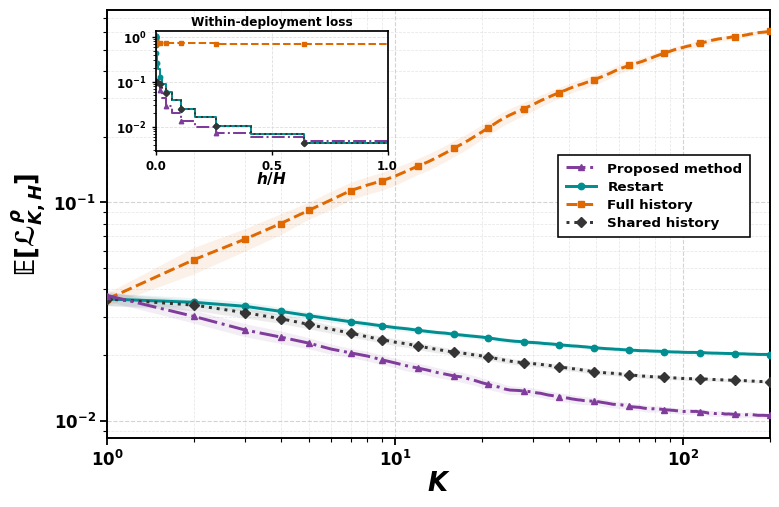


Plot-1_legend_inside: H=1,048,576, epsilon=0.02
Final 20% of deployments: mean +/- 95% CI
  Proposed method      0.010383 +/- 0.000518
  Restart              0.019495 +/- 0.000435
  Full history         0.715092 +/- 0.034219
  Shared history       0.014464 +/- 0.000439
  Proposed reduction versus Shared history: 28.2%


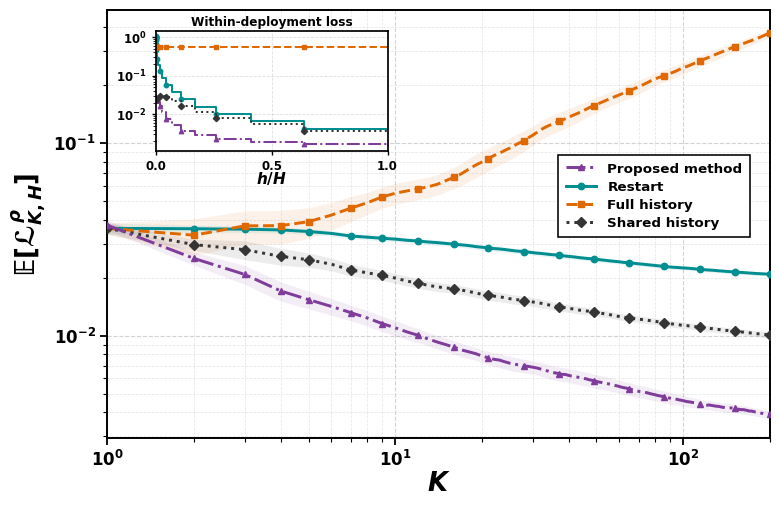


Plot-2_legend_inside: H=1,048,576, epsilon=0.005
Final 20% of deployments: mean +/- 95% CI
  Proposed method      0.003022 +/- 0.000256
  Restart              0.019151 +/- 0.000709
  Full history         0.558576 +/- 0.050716
  Shared history       0.008694 +/- 0.000531
  Proposed reduction versus Shared history: 65.2%

Saved figures and tables to: /content/DeployQ_Results/replot/original_plots


In [6]:
# Archive indices are deliberately explicit: 5 is the black curve in the PDFs.
PLOT_METHODS = [4, 0, 1, 5]
PLOT_LABELS = {4: 'Proposed method', 0: 'Restart', 1: 'Full history', 5: 'Shared history'}
COLORS = {4: '#803c9b', 0: '#008e91', 1: '#df6800', 5: '#353535'}
LINES = {4: '-.', 0: '-', 1: '--', 5: ':'}
MARKERS = {4: '^', 0: 'o', 1: 's', 5: 'D'}
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 12, 'font.weight': 'bold',
    'axes.labelweight': 'bold', 'axes.linewidth': 1.4,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'mathtext.fontset': 'dejavusans', 'xtick.major.width': 1.3,
    'ytick.major.width': 1.3, 'savefig.dpi': 300,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'path.simplify': False,
})

def mean_ci(samples):
    samples = np.asarray(samples)
    mean = samples.mean(axis=0)
    half = student_t.ppf(0.975, len(samples)-1) * samples.std(axis=0, ddof=1) / np.sqrt(len(samples))
    return mean, half

def save_figure(fig, filename, title):
    fig.savefig(RUN_DIR / f'{filename}.png', dpi=300)
    fig.savefig(RUN_DIR / f'{filename}.pdf', metadata={'Title': title})
    plt.show()
    plt.close(fig)

def plot_tracking(record, filename):
    cfg = record['config']
    x = np.arange(1, cfg['K']+1)
    indices = np.unique(np.r_[0, np.geomspace(1, cfg['K'], 20).astype(int)-1])
    fig, ax = plt.subplots(figsize=(8, 5))
    fig.subplots_adjust(left=.143, right=.971, bottom=.121, top=.977)
    for m in PLOT_METHODS:
        mean, ci = record['cumulative_mean'][:, m], record['cumulative_ci'][:, m]
        ax.plot(x, mean, color=COLORS[m], ls=LINES[m], lw=2.13,
                marker=MARKERS[m], markersize=4.6, markevery=indices.tolist(),
                label=PLOT_LABELS[m], zorder=6 if m == 4 else 4)
        ax.fill_between(x, np.maximum(mean-ci, 1e-5), mean+ci,
                        color=COLORS[m], alpha=.09, linewidth=0)
    ax.set(xscale='log', yscale='log', xlim=(1, cfg['K']))
    ax.set_xlabel(r'$K$', fontsize=18.5, labelpad=1)
    ax.set_ylabel(r'$\mathrm{𝔼}[ℒ_{K,H}^{\rho}]$', fontsize=18.5, labelpad=3)
    ax.grid(True, which='major', color='#bcbcbc', linestyle='--', alpha=.65, linewidth=.8)
    ax.grid(True, which='minor', color='#d0d0d0', linestyle='--', alpha=.5, linewidth=.55)
    ax.tick_params(which='major', length=5)
    ax.tick_params(which='minor', length=3, width=.8)
    ax.set_axisbelow(True)

    legend = ax.legend(loc='center right', bbox_to_anchor=(.98, .565),
                       fontsize=9.7, framealpha=1, edgecolor='black',
                       fancybox=False, handlelength=2.3, borderpad=.55,
                       labelspacing=.38)
    legend.get_frame().set_linewidth(1.15)

    inset = ax.inset_axes([.073, .67, .35, .28])
    h = record['grid'] / cfg['H']
    inset_losses = record['inset_mean']
    for m in PLOT_METHODS:
        values = inset_losses[:, m]
        inset.plot(h, np.r_[values, values[-1]], color=COLORS[m], ls=LINES[m],
                   lw=1.45, marker=MARKERS[m], markersize=3.2, markevery=2,
                   drawstyle='steps-post')
    inset.set(xlim=(0, 1), yscale='log')
    inset.set_ylim(bottom=max(1e-5, inset_losses[:, PLOT_METHODS][inset_losses[:, PLOT_METHODS] > 0].min()*.65))
    inset.set_xticks([0, .5, 1])
    inset.tick_params(labelsize=8.5, length=3, width=1)
    inset.set_title('Within-deployment loss', fontsize=8.7, pad=4, fontweight='bold')
    inset.set_xlabel(r'$h/H$', fontsize=11, labelpad=-2)
    inset.grid(True, color='#cccccc', ls='--', alpha=.65, linewidth=.6)
    for spine in inset.spines.values():
        spine.set_linewidth(1.25)

    save_figure(fig, filename, f'Policy loss, epsilon = {cfg["epsilon"]}')

summary_rows, paired_rows = [], []
for record in plot_records:
    cfg, late = record['config'], record['late_samples']
    if cfg['benchmark'] == 'localized' and cfg['H'] == 2**20 and cfg['epsilon'] == 0.02:
        filename = 'Plot-1_legend_inside'
    elif cfg['benchmark'] == 'localized' and cfg['H'] == 2**20 and cfg['epsilon'] == 0.005:
        filename = 'Plot-2_legend_inside'
    else:
        filename = f'{cfg["benchmark"]}_H{cfg["H"]}_eps{cfg["epsilon"]:g}'
    plot_tracking(record, filename)
    print(f'\n{filename}: H={cfg["H"]:,}, epsilon={cfg["epsilon"]}')
    print('Final 20% of deployments: mean +/- 95% CI')
    for m in PLOT_METHODS:
        mean, half = mean_ci(late[:, m])
        label = PLOT_LABELS[m]
        print(f'  {label:20s} {mean:.6f} +/- {half:.6f}')
        summary_rows.append(dict(
            figure=filename, benchmark=cfg['benchmark'], H=cfg['H'],
            epsilon=cfg['epsilon'], runs=cfg['runs'], K=cfg['K'],
            method=label, archive_method_index=m, late_mean=float(mean),
            ci95_lower=float(mean-half), ci95_upper=float(mean+half),
            all_deployments_mean=float(record['cumulative_mean'][-1, m]),
        ))
        if m != 4:
            difference, diff_half = mean_ci(late[:, m]-late[:, 4])
            paired_rows.append(dict(
                figure=filename, baseline=label,
                baseline_minus_proposed=float(difference),
                paired_ci95_lower=float(difference-diff_half),
                paired_ci95_upper=float(difference+diff_half),
            ))
    baseline_mean = late[:, 5].mean()
    reduction = 1-late[:, 4].mean()/baseline_mean if baseline_mean > 0 else float('nan')
    print(f'  Proposed reduction versus Shared history: {100*reduction:.1f}%')

def write_csv(path, records):
    with path.open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows(records)

write_csv(RUN_DIR / 'summary.csv', summary_rows)
write_csv(RUN_DIR / 'paired_comparisons.csv', paired_rows)
print('\nSaved figures and tables to:', RUN_DIR)
